# TN3K · U-Net 3+ · final test

Bu notebook, 62. epoch ağırlığını 614 resmî test görüntüsünde değerlendirir. Eğitim kayıtları, ortak ayrım ve tek örnek kontrolü geçtikten sonra tam test başlar.

Ana Drive klasörleri aşağıdaki yollarla eşleşiyorsa yalnız Colab çalışma zamanı seç. Varsayılan çalışma ayarı GPU bekler. CPU ile test etmek için `DEVICE_MODE = "cpu"` seç. Hata alırsan ilgili hücrenin başlığını ve çıktısını paylaş.

## 1 · Ayarlar ve Drive bağlantısı

Deney, veri ve Base U-Net sonuç yollarını burada düzenle. GPU seçtiysen çıktıdaki cihaz adını kontrol et.

In [1]:
from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/TN3K")
EXPERIMENT_DIR = PROJECT / "UNet3" / "Colab_T4_Sifirdan_01"
CHECKPOINT_PATH = EXPERIMENT_DIR / "best_unet3plus.pt"
BASE_RESULTS_DIR = (
    PROJECT / "BaseUNet" / "Test_Sonuclari" / "Base_UNet_Epoch27_20261124T160223Z_a8532dfd"
)
MANIFEST_PATH = BASE_RESULTS_DIR / "verified_split_manifest.csv"
OUTPUT_ROOT = PROJECT / "UNet3" / "Test_Sonuclari"
DATASET_ROOT = ""  # Boşsa TN3K v2 otomatik hazırlanır.
DEVICE_MODE = "cuda"  # GPU atanmadıysa CPU için açıkça "cpu" yaz.

from google.colab import drive
import torch

drive.mount("/content/drive")
cuda_available = torch.cuda.is_available()
print("CUDA kullanılabilir:", cuda_available)
if cuda_available:
    print("GPU:", torch.cuda.get_device_name(0))
if DEVICE_MODE not in {"cuda", "cpu"}:
    raise ValueError('DEVICE_MODE için "cuda" veya "cpu" seç.')
if DEVICE_MODE == "cuda" and not cuda_available:
    raise RuntimeError('GPU atanmadı. Colab’da GPU seçip yeniden bağlan veya DEVICE_MODE = "cpu" yap.')
device = torch.device(DEVICE_MODE)
print("Değerlendirme cihazı:", device)

Mounted at /content/drive
CUDA kullanılabilir: True
GPU: Tesla T4
Değerlendirme cihazı: cuda


## 2 · Eğitimin tamamlanması ve seçilen ağırlık

Tamamlanma kaydı, eğitim geçmişi ve checkpoint birbirini doğrulamalı. Son tamamlanan epoch ile en iyi doğrulama epoch’u ayrı gösterilir.

In [3]:
EXPECTED_MANIFEST_SHA256 = '8e7f07f36625f59bd0f233e8c4f84ecc4e0f181fbad77788c6513f1d4df6867b'
EXPECTED_CHECKPOINT_SHA256 = 'a64d9bc7b48779775593396a9e5341e8b031e9e542c7dd0f4848419f8c89dd38'

from dataclasses import dataclass
from datetime import datetime, timezone
from typing import Any
from uuid import uuid4
import hashlib
import json
import math
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from PIL import Image
from scipy import ndimage as ndi
from torch import nn
from torch.nn import functional as F
from torch.utils.checkpoint import checkpoint
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm

completed_path = EXPERIMENT_DIR / "training_completed.json"
history_path = EXPERIMENT_DIR / "history_unet3plus.csv"
settings_path = EXPERIMENT_DIR / "experiment.json"

def require_files(*paths):
    missing = [str(path) for path in paths if not path.is_file()]
    if missing:
        raise FileNotFoundError("Gerekli dosyalar bulunamadı:\n" + "\n".join(missing))

def sha256(content):
    return hashlib.sha256(content).hexdigest()

def read_json(path):
    return json.loads(path.read_text(encoding="utf-8"))

if not completed_path.is_file():
    raise FileNotFoundError(
        f"Eğitimin bittiği doğrulanamadı: {completed_path}. Eğitim özetinde "
        "erken durdurma veya toplam epoch sınırı görülmeli. Oturum sınırı tamamlanma sayılmaz."
    )
require_files(CHECKPOINT_PATH, history_path, settings_path, MANIFEST_PATH)
completed = read_json(completed_path)
spec = read_json(settings_path)
history = pd.read_csv(history_path)

checkpoint_digest = sha256(CHECKPOINT_PATH.read_bytes())
if checkpoint_digest != EXPECTED_CHECKPOINT_SHA256:
    raise ValueError(f"Checkpoint bu sohbet için doğrulanan 62. epoch dosyasıyla eşleşmiyor: {CHECKPOINT_PATH}")
state = torch.load(CHECKPOINT_PATH, map_location="cpu", weights_only=True)
if state["spec"] != spec:
    raise ValueError(f"Checkpoint ayarları {settings_path.name} ile eşleşmiyor.")
if spec["architecture"] != "UNet3Plus_no_deep_supervision" or spec["split_hash"] != EXPECTED_MANIFEST_SHA256:
    raise ValueError("Deney mimarisi veya ortak ayrım kimliği beklenen değerle uyuşmuyor.")
if completed["manifest_sha256"] != EXPECTED_MANIFEST_SHA256:
    raise ValueError(f"Manifest kimliği {completed_path.name} ile uyuşmuyor.")

last_epoch = completed["last_epoch"]
if last_epoch != 82 or history["epoch"].tolist() != list(range(1, last_epoch + 1)):
    raise ValueError(f"{history_path.name} ve {completed_path.name} uyuşmuyor. Epoch 1–82 bekleniyor.")
if not np.isfinite(history["val_dice"]).all():
    raise ValueError(f"Geçersiz doğrulama Dice değeri: {history_path}")

best_row = history.loc[history["val_dice"].idxmax()]
best_epoch = state["epoch"]
if (best_epoch != 62 or best_epoch != completed["best_epoch"] or best_epoch != int(best_row["epoch"])
        or not math.isclose(state["best_val_dice"], float(best_row["val_dice"]), rel_tol=0, abs_tol=1e-8)
        or not math.isclose(state["best_val_dice"], completed["best_val_dice"], rel_tol=0, abs_tol=1e-8)):
    raise ValueError("En iyi epoch veya Dice, checkpoint, geçmiş CSV’si ve tamamlanma kaydı arasında çelişiyor.")

saved_config = spec["config"]
patience_reference = -math.inf
stale_epochs = 0
for score in history["val_dice"]:
    if score > patience_reference + saved_config["early_stopping_min_delta"]:
        patience_reference, stale_epochs = score, 0
    else:
        stale_epochs += 1
reason = completed["reason"]
valid_stop = (
    reason == "Erken durdurma" and stale_epochs >= saved_config["early_stopping_patience"]
    or reason == "Deneyin toplam epoch sınırına ulaşıldı" and last_epoch == saved_config["epochs"]
)
if not valid_stop:
    raise ValueError(f"Tamamlanma nedeni ayarlar ve geçmişle doğrulanamadı: {reason}")

print("Deney:", saved_config["run_name"])
print("Son tamamlanan epoch:", last_epoch, "| Durma nedeni:", reason)
print(f"Seçilen checkpoint: {CHECKPOINT_PATH} | Epoch: {best_epoch} | Doğrulama Dice: {state['best_val_dice']:.4%}")

Deney: Colab_T4_Sifirdan_01
Son tamamlanan epoch: 82 | Durma nedeni: Erken durdurma
Seçilen checkpoint: /content/drive/MyDrive/TN3K/UNet3/Colab_T4_Sifirdan_01/best_unet3plus.pt | Epoch: 62 | Doğrulama Dice: 79.0378%


## 3 · Ortak manifest ve 614 test çifti

Manifesti checkpoint ile eşleştirir, dosyaları güncel test klasörlerinden açar ve her görüntü ile maskenin piksel kimliğini doğrular.

In [4]:
manifest_bytes = MANIFEST_PATH.read_bytes()
if sha256(manifest_bytes) != EXPECTED_MANIFEST_SHA256:
    raise ValueError(f"Doğrulanmış manifest hash’i eşleşmiyor: {MANIFEST_PATH}")
manifest = pd.read_csv(MANIFEST_PATH, dtype={"filename": str})
counts = manifest["subset"].value_counts().to_dict()
if counts != {"train": 2303, "val": 576, "test": 614}:
    raise ValueError(f"Manifest alt küme sayıları yanlış: {counts}")
test_table = manifest.loc[manifest["subset"].eq("test")].copy().reset_index(drop=True)
if (not test_table["split"].eq("test").all() or not test_table["filename"].is_unique
        or test_table["image_hash"].nunique() != 614):
    raise ValueError("Manifestte test kimliği veya görüntü içeriği yineleniyor ya da kaynak bölümü hatalı.")

if DATASET_ROOT.strip():
    data_root = Path(DATASET_ROOT.strip()).expanduser().resolve()
else:
    try:
        import kagglehub
    except ModuleNotFoundError:
        import subprocess
        import sys
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "kagglehub"])
        import kagglehub
    data_root = Path(kagglehub.dataset_download(spec["dataset_source"])).resolve()

names = set(test_table["filename"])
for kind in ("image", "mask"):
    folder = data_root / f"test-{kind}"
    if not folder.is_dir():
        raise FileNotFoundError(f"Test klasörü bulunamadı: {folder}. DATASET_ROOT alanını kontrol et.")
    present = {file.name for file in folder.glob("*.jpg")}
    if present != names:
        raise ValueError(f"{folder} | Eksik: {sorted(names - present)[:5]} | Fazla: {sorted(present - names)[:5]}")
    test_table[f"{kind}_path"] = [str(folder / name) for name in test_table["filename"]]

for row in tqdm(test_table.itertuples(index=False), total=len(test_table), desc="Test çiftleri doğrulanıyor"):
    for kind in ("image", "mask"):
        path = getattr(row, f"{kind}_path")
        with Image.open(path) as source:
            pixels = np.asarray(source.convert("L"))
            if kind == "mask":
                pixels = (pixels >= saved_config["mask_threshold"]).astype(np.uint8)
            digest = sha256(str(pixels.shape).encode() + pixels.tobytes())
        if pixels.shape != (row.height, row.width) or digest != getattr(row, f"{kind}_hash"):
            raise ValueError(f"Boyut veya piksel kimliği manifestle eşleşmiyor: {path}")

print("TN3K veri kökü:", data_root)
print("Doğrulanan test çifti:", len(test_table))
print("Base U-Net ile ortak manifest SHA-256:", EXPECTED_MANIFEST_SHA256)

100%|██████████| 176M/176M [00:10<00:00, 17.7MB/s]

Extracting files...


Test çiftleri doğrulanıyor:   0%|          | 0/614 [00:00<?, ?it/s]

TN3K veri kökü: /root/.cache/kagglehub/datasets/tjahan/tn3k-thyroid-nodule-region-segmentation-dataset/versions/2
Doğrulanan test çifti: 614
Base U-Net ile ortak manifest SHA-256: 8e7f07f36625f59bd0f233e8c4f84ecc4e0f181fbad77788c6513f1d4df6867b


## 4 · U-Net 3+ ve Base ile ortak test işlemleri

Eğitimdeki mimariyi kurar ve ağırlıkları katman katman doğrular. Base testindeki ön işlemeyi, 0,5 eşiğini ve FP32 hesaplamayı kullanır.

In [5]:
@dataclass(frozen=True)
class Config:
    """Bütün deney seçimleri; EDA ROOT ve SEED değerlerini devralır."""
    root: Path
    seed: int
    output_root: Path = Path.cwd() / 'tn3k_training'
    run_name: str = 'native_unet_image_split_01'
    pad_multiple: int = 32
    fixed_input_hw: tuple[int, int] | None = None  # Alternatif: (832, 1472); resize DEĞİL.
    input_channels: int = 1
    mask_threshold: int = 128
    intensity_scale: float = 255.0
    padding_value: float = 0.0
    foreground_value: float = 1.0
    prediction_threshold: float = 0.5
    validation_fraction: float = 0.20
    normalization: str = 'scale'  # 'scale' veya ayrı ablation için 'zscore'.
    horizontal_flip_probability: float = 0.5
    batch_size: int = 1
    num_workers: int = 0  # Notebook / Windows / Colab için güvenli varsayılan.
    pin_memory: bool = True
    base_channels: int = 16
    depth: int = 4
    norm_groups: int = 4
    conv_kernel: int = 3
    downsample_factor: int = 2
    epochs: int = 100
    learning_rate: float = 1e-3
    weight_decay: float = 1e-4
    gradient_accumulation: int = 4
    gradient_clip: float = 1.0
    loss_kind: str = 'bce_dice'  # Alternatif: 'focal_dice'.
    pixel_loss_weight: float = 0.5
    focal_alpha: float = 0.75
    focal_gamma: float = 2.0
    epsilon: float = 1e-6
    lr_factor: float = 0.5
    lr_patience: int = 5
    min_learning_rate: float = 1e-6
    early_stopping_patience: int = 20
    early_stopping_min_delta: float = 1e-4
    use_amp: bool = True
    activation_checkpointing: bool = True
    deterministic: bool = True
    device: str = 'auto'
    cublas_workspace_config: str = ':4096:8'
    hd_percentile: float = 95.0
    surface_connectivity: int = 1
    small_area_quantile: float = 0.25
    sanity_examples: int = 4
    prediction_examples: int = 4
    overlay_alpha: float = 0.4
    figure_dpi: int = 140

    @property
    def input_shape(self) -> tuple[int, int | None, int | None]:
        """PyTorch C,H,W; None özgün boyuta göre dinamik padding demektir."""
        return (self.input_channels, *(self.fixed_input_hw or (None, None)))

    @property
    def run_dir(self) -> Path:
        return self.output_root / self.run_name

    @property
    def manifest_path(self) -> Path:
        return self.run_dir / 'split_manifest.csv'

    @property
    def best_checkpoint_path(self) -> Path:
        return self.run_dir / 'best.pt'

    @property
    def history_path(self) -> Path:
        return self.run_dir / 'history.csv'

    @property
    def test_dir(self) -> Path:
        return self.run_dir / 'final_test'

    def validate(self) -> None:
        """Gizli resize/fallback yerine geçersiz ayarları açıkça reddet."""
        if not self.root.is_dir():
            raise ValueError(f'EDA ROOT bulunamadı: {self.root}')
        if self.batch_size != 1:
            raise ValueError('Bu değişken boyutlu uygulamada batch_size=1; etkili batch için accumulation kullan.')
        divisor = self.downsample_factor ** self.depth
        if self.downsample_factor != 2 or self.depth < 1 or self.pad_multiple % divisor:
            raise ValueError('pad_multiple, 2**depth ile tam bölünmeli; downsample_factor=2 olmalı.')
        if self.base_channels < self.norm_groups or self.base_channels % self.norm_groups:
            raise ValueError('base_channels norm_groups ile bölünebilmeli.')
        if self.conv_kernel % 2 == 0:
            raise ValueError('Aynı boyutu korumak için tek sayılı convolution kernel gerekli.')
        if self.padding_value != 0.0 or self.foreground_value != 1.0 or self.input_channels != 1:
            raise ValueError('Bu sürüm grayscale giriş, sıfır padding ve {0,1} maske kullanır.')
        if not 0 < self.validation_fraction < 1 or not 0 < self.prediction_threshold < 1:
            raise ValueError('Split ve tahmin eşikleri (0,1) aralığında olmalı.')
        if not 0 <= self.horizontal_flip_probability <= 1 or not 0 <= self.pixel_loss_weight <= 1:
            raise ValueError('Olasılık/ağırlık aralığı [0,1] olmalı.')
        if self.normalization not in ('scale', 'zscore') or self.loss_kind not in ('bce_dice', 'focal_dice'):
            raise ValueError('Bilinmeyen normalizasyon veya loss.')
        if min(self.epochs, self.gradient_accumulation, self.early_stopping_patience) < 1:
            raise ValueError('Epoch, accumulation ve patience pozitif olmalı.')
        if self.fixed_input_hw and any(s <= 0 or s % self.pad_multiple for s in self.fixed_input_hw):
            raise ValueError('Sabit canvas boyutları pozitif pad_multiple katları olmalı.')

def read_image_mask(image_path: str | Path, mask_path: str | Path, config: Config) -> tuple[np.ndarray, np.ndarray]:
    """EDA gibi PIL convert('L') kullan; önce maskeyi ikilileştir, resize yapma."""
    with Image.open(image_path) as image, Image.open(mask_path) as mask:
        if image.size != mask.size:
            raise ValueError(f'Görüntü/maske boyutu farklı: {image_path}')
        x = np.asarray(image.convert('L')).copy()
        y = (np.asarray(mask.convert('L')) >= config.mask_threshold).astype(np.uint8)
    return x, y

@dataclass(frozen=True)
class SpatialInfo:
    """Tahmini özgün koordinata döndürmek için saklanan boyutlar."""
    height: int
    width: int
    padded_height: int
    padded_width: int

def normalize_intensity(image: np.ndarray, config: Config) -> np.ndarray:
    """GT kullanmadan, padding eklenmeden önce yoğunluk ölçekle."""
    result = image.astype(np.float32) / config.intensity_scale
    if config.normalization == 'zscore':
        result = (result - result.mean()) / max(float(result.std()), config.epsilon)
    return result

def pad_without_resampling(image: np.ndarray, mask: np.ndarray, config: Config
                          ) -> tuple[np.ndarray, np.ndarray, np.ndarray, SpatialInfo]:
    """Sağ/alt padding; tüm kaynak pikselleri ve nodül etiketlerini birebir koru."""
    if image.shape != mask.shape or image.ndim != 2:
        raise ValueError('Ön işleme 2D eş boyutlu görüntü/maske bekliyor.')
    if not np.isin(mask, [config.padding_value, config.foreground_value]).all():
        raise ValueError('Maske ikili değil.')
    height, width = image.shape
    multiple = config.pad_multiple
    target_h, target_w = config.fixed_input_hw or (
        math.ceil(height / multiple) * multiple, math.ceil(width / multiple) * multiple)
    if target_h < height or target_w < width:
        raise ValueError('Canvas görüntüden küçük. Resize/crop yasak: canvas büyüt veya dinamik kullan.')
    padding = ((0, target_h - height), (0, target_w - width))
    padded_image = np.pad(image, padding, constant_values=config.padding_value)
    padded_mask = np.pad(mask, padding, constant_values=config.padding_value)
    valid = np.pad(np.ones(mask.shape, np.float32), padding, constant_values=config.padding_value)
    if not np.array_equal(padded_image[:height, :width], image):
        raise AssertionError('Görüntü pikselleri değişti.')
    if not np.array_equal(padded_mask[:height, :width], mask) or padded_mask.sum() != mask.sum():
        raise AssertionError('Maske pikselleri kayboldu veya yer değiştirdi.')
    return padded_image, padded_mask, valid, SpatialInfo(height, width, target_h, target_w)

def preprocess_native_pair(image_path: str | Path, mask_path: str | Path, config: Config,
                           augment: bool = False) -> tuple[np.ndarray, np.ndarray, np.ndarray, SpatialInfo]:
    """EDA preprocess_pair örneğinden ayrı, eğitimde kullanılan kayıpsız geometri."""
    image, mask = read_image_mask(image_path, mask_path, config)
    if augment and random.random() < config.horizontal_flip_probability:
        image, mask = np.fliplr(image).copy(), np.fliplr(mask).copy()
    return pad_without_resampling(normalize_intensity(image, config), mask, config)

class ThyroidNoduleDataset(Dataset):
    """EDA yollarını kullanır; yalnız train için ortak yatay flip uygular."""
    def __init__(self, table: pd.DataFrame, config: Config, augment: bool = False) -> None:
        self.table = table.reset_index(drop=True).copy()
        self.config = config
        self.augment = augment

    def __len__(self) -> int:
        return len(self.table)

    def __getitem__(self, index: int) -> dict[str, Any]:
        row = self.table.iloc[index]
        image, mask, valid, info = preprocess_native_pair(row.image_path, row.mask_path, self.config, self.augment)
        tensors = {name: torch.from_numpy(np.ascontiguousarray(array[None], dtype=np.float32))
                   for name, array in [('image', image), ('mask', mask), ('valid', valid)]}
        return {**tensors, 'height': info.height, 'width': info.width, 'index': index}

def seed_worker(worker_id: int) -> None:
    """DataLoader alt süreçlerinin Python/NumPy RNG durumlarını sabitle."""
    worker_seed = torch.initial_seed() % (2 ** 32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)

def make_loader(table: pd.DataFrame, config: Config, training: bool = False) -> DataLoader:
    """Bir batch bir görüntü; farklı boyutları stack etme ihtiyacı yok."""
    generator = torch.Generator().manual_seed(config.seed)
    return DataLoader(ThyroidNoduleDataset(table, config, augment=training), batch_size=config.batch_size,
                      shuffle=training, num_workers=config.num_workers, worker_init_fn=seed_worker,
                      generator=generator, pin_memory=config.pin_memory and select_device(config).type == 'cuda')

def select_device(config: Config) -> torch.device:
    """GPU yoksa CPU; istenen CUDA yoksa sessiz fallback yerine hata."""
    name = ('cuda' if torch.cuda.is_available() else 'cpu') if config.device == 'auto' else config.device
    if name.startswith('cuda') and not torch.cuda.is_available():
        raise RuntimeError('CUDA istendi fakat kullanılamıyor.')
    return torch.device(name)

class DoubleConvolution(nn.Module):
    """Same-padding convolution + GroupNorm: batch=1 için kararlı blok."""
    def __init__(self, in_channels: int, out_channels: int, config: Config) -> None:
        super().__init__()
        padding = config.conv_kernel // 2
        self.layers = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, config.conv_kernel, padding=padding, bias=False),
            nn.GroupNorm(config.norm_groups, out_channels), nn.ReLU(),
            nn.Conv2d(out_channels, out_channels, config.conv_kernel, padding=padding, bias=False),
            nn.GroupNorm(config.norm_groups, out_channels), nn.ReLU())

    def forward(self, tensor: torch.Tensor) -> torch.Tensor:
        return self.layers(tensor)

class NativeResolutionUNet3Plus(nn.Module):
    """Full-scale skip bağlantıları olan, tek çıkışlı 2D U-Net 3+."""

    def __init__(self, config, branch_channels: int = 8):
        super().__init__()
        self.config = config
        self.depth = config.depth

        if branch_channels % config.norm_groups != 0:
            raise ValueError("branch_channels, norm_groups ile tam bölünmeli.")

        encoder_widths = [
            config.base_channels * 2**level
            for level in range(self.depth + 1)
        ]
        fusion_width = (self.depth + 1) * branch_channels

        self.encoder = nn.ModuleList([
            DoubleConvolution(in_channels, out_channels, config)
            for in_channels, out_channels in zip(
                [config.input_channels] + encoder_widths[:-1],
                encoder_widths,
            )
        ])

        self.projections = nn.ModuleDict()
        self.fusions = nn.ModuleDict()

        for level in reversed(range(self.depth)):
            source_widths = (
                encoder_widths[:level + 1]
                + [fusion_width] * (self.depth - level - 1)
                + [encoder_widths[-1]]
            )

            self.projections[str(level)] = nn.ModuleList([
                nn.Sequential(
                    nn.Conv2d(
                        width, branch_channels, kernel_size=3,
                        padding=1, bias=False,
                    ),
                    nn.GroupNorm(config.norm_groups, branch_channels),
                    nn.ReLU(),
                )
                for width in source_widths
            ])

            self.fusions[str(level)] = DoubleConvolution(
                fusion_width, fusion_width, config
            )

        self.output = nn.Conv2d(fusion_width, 1, kernel_size=1)

    def _apply_block(self, block, x):
        if self.training and self.config.activation_checkpointing:
            return checkpoint(block, x, use_reentrant=False)
        return block(x)

    @staticmethod
    def _match_size(x, target_hw):
        """Özellik haritasını hedef decoder seviyesinin boyutuna getir."""
        height, width = x.shape[-2:]
        target_height, target_width = target_hw

        if (height, width) == (target_height, target_width):
            return x

        # Küçültme: birbirine taşmayan, sabit pencereli max pooling.
        if height >= target_height and width >= target_width:
            if height % target_height == 0 and width % target_width == 0:
                factor = (height // target_height, width // target_width)
                return F.max_pool2d(x, kernel_size=factor, stride=factor)

        # Büyütme: her özellik değerini tam sayı katsayısıyla tekrarla.
        if height <= target_height and width <= target_width:
            if target_height % height == 0 and target_width % width == 0:
                scale_h = target_height // height
                scale_w = target_width // width
                batch, channels = x.shape[:2]

                return (
                    x.reshape(batch, channels, height, 1, width, 1)
                    .expand(batch, channels, height, scale_h, width, scale_w)
                    .reshape(batch, channels, target_height, target_width)
                )

        raise ValueError(
            f"Özellik haritası boyutları tam kat olmalı. "
            f"Kaynak {(height, width)}, hedef {(target_height, target_width)}."
        )

    def forward(self, x):
        divisor = 2**self.depth
        if any(size % divisor != 0 for size in x.shape[-2:]):
            raise ValueError(
                f"Girdi yüksekliği ve genişliği {divisor} katı olmalı."
            )

        encoder_features = []
        for level, block in enumerate(self.encoder):
            if level > 0:
                x = F.max_pool2d(x, kernel_size=2, stride=2)
            x = self._apply_block(block, x)
            encoder_features.append(x)

        decoder_features = {}
        for level in reversed(range(self.depth)):
            target_hw = encoder_features[level].shape[-2:]
            sources = (
                encoder_features[:level + 1]
                + [
                    decoder_features[k]
                    for k in range(level + 1, self.depth)
                ]
                + [encoder_features[-1]]
            )

            projected = [
                self._apply_block(
                    projection, self._match_size(feature, target_hw)
                )
                for projection, feature in zip(
                    self.projections[str(level)], sources
                )
            ]

            decoder_features[level] = self._apply_block(
                self.fusions[str(level)], torch.cat(projected, dim=1)
            )

        return self.output(decoder_features[0])

class MaskedSegmentationLoss(nn.Module):
    """Gerçek piksel alanında BCE/Focal + soft Dice; padding'e loss verme."""
    def __init__(self, config: Config) -> None:
        super().__init__()
        self.config = config

    def forward(self, logits: torch.Tensor, target: torch.Tensor, valid: torch.Tensor) -> torch.Tensor:
        logits, target, valid = logits.float(), target.float(), valid.float()
        probability = logits.sigmoid()
        pixel_loss = F.binary_cross_entropy_with_logits(logits, target, reduction='none')
        if self.config.loss_kind == 'focal_dice':
            probability_true = probability * target + (1 - probability) * (1 - target)
            alpha = self.config.focal_alpha * target + (1 - self.config.focal_alpha) * (1 - target)
            pixel_loss = alpha * (1 - probability_true).pow(self.config.focal_gamma) * pixel_loss
        axes = (1, 2, 3)
        pixel_loss = (pixel_loss * valid).sum(axes) / valid.sum(axes).clamp_min(self.config.epsilon)
        intersection = (probability * target * valid).sum(axes)
        denominator = (probability * valid).sum(axes) + (target * valid).sum(axes)
        dice_loss = 1 - (2 * intersection + self.config.epsilon) / (denominator + self.config.epsilon)
        weight = self.config.pixel_loss_weight
        return (weight * pixel_loss + (1 - weight) * dice_loss).mean()

def overlap_scores(prediction: np.ndarray, target: np.ndarray) -> dict[str, float | bool]:
    """Tek görüntü Dice/IoU; boş maske politikasını açık tanımla."""
    prediction, target = prediction.astype(bool), target.astype(bool)
    intersection = np.logical_and(prediction, target).sum()
    denominator = prediction.sum() + target.sum()
    union = np.logical_or(prediction, target).sum()
    return {'dice': float(2 * intersection / denominator) if denominator else 1.0,
            'iou': float(intersection / union) if union else 1.0,
            'empty_prediction': bool(not prediction.any()), 'empty_target': bool(not target.any())}

def surface_hd95(prediction: np.ndarray, target: np.ndarray, config: Config) -> float:
    """İki yönlü yüzey uzaklığı p95 maksimumu, özgün piksel birimi."""
    prediction, target = prediction.astype(bool), target.astype(bool)
    if not prediction.any() and not target.any():
        return 0.0
    if not prediction.any() or not target.any():
        return float('inf')
    structure = ndi.generate_binary_structure(2, config.surface_connectivity)
    prediction_surface = prediction ^ ndi.binary_erosion(prediction, structure=structure, border_value=0)
    target_surface = target ^ ndi.binary_erosion(target, structure=structure, border_value=0)
    to_target = ndi.distance_transform_edt(~target_surface)[prediction_surface]
    to_prediction = ndi.distance_transform_edt(~prediction_surface)[target_surface]
    return float(max(np.percentile(to_target, config.hd_percentile), np.percentile(to_prediction, config.hd_percentile)))

def scores_from_logits(logits: torch.Tensor, batch: dict[str, Any], config: Config, include_hd: bool = False
                      ) -> tuple[dict[str, Any], np.ndarray]:
    """Yalnız yapay padding'i kaldır; görüntünün özgün alanında metrik hesapla."""
    height, width = int(batch['height'].item()), int(batch['width'].item())
    prediction = (logits.detach().float().sigmoid()[0, 0, :height, :width].cpu().numpy() >= config.prediction_threshold)
    target = batch['mask'][0, 0, :height, :width].cpu().numpy().astype(bool)
    scores = overlap_scores(prediction, target)
    if include_hd:
        scores['hd95_px'] = surface_hd95(prediction, target, config)
    return scores, prediction

def summarize_metrics(results: pd.DataFrame) -> dict[str, Any]:
    """Macro skorlar; tanımsız HD95 vakalarını gizlemeden ayrı raporla."""
    finite = np.isfinite(results.hd95_px)
    return {'images': len(results), 'unique_images': int(results.image_hash.nunique()),
            'dice_mean': float(results.dice.mean()), 'dice_std': float(results.dice.std(ddof=0)),
            'iou_mean': float(results.iou.mean()), 'iou_std': float(results.iou.std(ddof=0)),
            'hd95_mean_px': float(results.hd95_px.mean()) if finite.all() else None,
            'hd95_finite_mean_px': float(results.loc[finite, 'hd95_px'].mean()) if finite.any() else None,
            'hd95_nonfinite_cases': int((~finite).sum()), 'empty_predictions': int(results.empty_prediction.sum())}


protocol_keys = (
    "input_channels", "mask_threshold", "intensity_scale", "normalization", "pad_multiple",
    "fixed_input_hw", "padding_value", "foreground_value", "prediction_threshold", "batch_size",
    "hd_percentile", "surface_connectivity",
)
base_test_protocol = dict(
    input_channels=1, mask_threshold=128, intensity_scale=255.0, normalization="scale",
    pad_multiple=32, fixed_input_hw=None, padding_value=0.0, foreground_value=1.0,
    prediction_threshold=0.5, batch_size=1, hd_percentile=95.0, surface_connectivity=1,
)
if any(saved_config.get(key) != base_test_protocol[key] for key in protocol_keys):
    raise ValueError("Checkpoint ön işleme veya metrik ayarları Base U-Net test protokolüyle uyuşmuyor.")
cfg = Config(**{**saved_config, "root": data_root, "output_root": OUTPUT_ROOT, "device": DEVICE_MODE})
cfg.validate()

model = NativeResolutionUNet3Plus(cfg, branch_channels=spec["branch_channels"]).to(device)
model.load_state_dict(state["model_state"], strict=True)
model.eval()
criterion = MaskedSegmentationLoss(cfg)
test_loader = make_loader(test_table, cfg, training=False)
if device.type == "cuda":
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False

@torch.inference_mode()
def predict_batch(batch, include_hd=False):
    image, target, valid = (batch[key].to(device) for key in ("image", "mask", "valid"))
    logits = model(image)
    loss = criterion(logits, target, valid)
    if not torch.isfinite(loss):
        raise FloatingPointError("Değerlendirme kaybı sonlu değil.")
    scores, prediction = scores_from_logits(logits, batch, cfg, include_hd=include_hd)
    return {**scores, "loss": loss.item()}, prediction

print("U-Net 3+ mimarisi ve ağırlıklar eşleşti. Tahmin eşiği: 0,5 | FP32 | Veri artırma kapalı.")

U-Net 3+ mimarisi ve ağırlıklar eşleşti. Tahmin eşiği: 0,5 | FP32 | Veri artırma kapalı.


## 5 · Tek örnekte boyut kontrolü

Ultrasonun, referans maskenin ve özgün boyuta geri alınan tahminin boyutları aynı olmalı.

In [6]:
example = test_table.iloc[0]
image, target = read_image_mask(example.image_path, example.mask_path, cfg)
batch = next(iter(test_loader))
_, prediction = predict_batch(batch)

print(f"{example.filename} · görüntü: {image.shape} · referans: {target.shape} · "
      f"tahmin: {prediction.shape} · dolgulu girdi: {tuple(batch['image'].shape)}")
if image.shape != target.shape or image.shape != prediction.shape:
    raise ValueError("Test örneğinde özgün boyutlar eşleşmedi.")
smoke_checked_model = model

0000.jpg · görüntü: (332, 365) · referans: (332, 365) · tahmin: (332, 365) · dolgulu girdi: (1, 1, 352, 384)


## 6 · Final test ve Drive kaydı

614 görüntüyü işler ve tahmin maskelerini özgün boyutta kaydeder. Özet JSON, tam test ve dosya kontrolleri geçince yazılır.

In [7]:
if smoke_checked_model is not model or sha256(manifest_bytes) != EXPECTED_MANIFEST_SHA256:
    raise RuntimeError("Önce ayrım ve tek görüntü kontrollerini tamamla.")
expected_test_count = 614
label = "U-Net 3+ · epoch 62"
timestamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
run_dir = OUTPUT_ROOT / f"UNet3Plus_Epoch62_{timestamp}_{uuid4().hex[:8]}"
prediction_dir = run_dir / "predictions"
prediction_dir.mkdir(parents=True, exist_ok=False)
print("Çıktı klasörü:", run_dir)

records = []
for batch in tqdm(test_loader, total=expected_test_count, desc="Resmî TN3K testi", unit="görüntü"):
    row = test_table.iloc[int(batch["index"].item())]
    scores, prediction = predict_batch(batch, include_hd=True)
    mask_filename = f"{row['split']}_{Path(row['filename']).stem}.png"
    Image.fromarray(prediction.astype(np.uint8) * 255).save(prediction_dir / mask_filename)
    records.append({"split": row["split"], "filename": row["filename"],
                    "image_hash": row["image_hash"], "foreground_pixels": int(row["foreground_pixels"]),
                    "prediction_file": mask_filename, **scores})

results = pd.DataFrame(records)
if len(results) != expected_test_count or results["image_hash"].nunique() != expected_test_count:
    raise RuntimeError(f"Test tamamlanmadı. Beklenen: {expected_test_count}, işlenen: {len(results)}.")


identity = ["split", "filename", "image_hash"]
expected_ids = test_table[identity].sort_values(identity).reset_index(drop=True)
if not expected_ids.equals(results[identity].sort_values(identity).reset_index(drop=True)):
    raise RuntimeError("İşlenen örnek kimlikleri doğrulanmış manifestle uyuşmuyor.")
if {path.name for path in prediction_dir.glob("*.png")} != set(results["prediction_file"]):
    raise RuntimeError("Tahmin PNG listesi görüntü bazlı kayıtlarla uyuşmuyor.")

results["small_nodule"] = results["foreground_pixels"] <= state["small_area_cutoff"]
results.to_csv(run_dir / "per_image_metrics.csv", index=False)
(run_dir / "verified_split_manifest.csv").write_bytes(manifest_bytes)
summary = {
    "status": "completed", "label": label, "checkpoint": str(CHECKPOINT_PATH),
    "checkpoint_sha256": checkpoint_digest, "checkpoint_epoch": best_epoch,
    "validation_dice": state["best_val_dice"], "last_training_epoch": last_epoch,
    "training_stop_reason": reason, "experiment": saved_config["run_name"],
    "manifest_sha256": EXPECTED_MANIFEST_SHA256, "expected_test_images": expected_test_count,
    "processed_test_images": len(results), "dataset_root": str(data_root),
    "device": str(device), "amp_enabled": False, "precision": "float32",
    "evaluation_unit": "image", "hd95_unit": "native pixel",
    "hd95_definition": "max of directed surface p95; one-sided empty mask = inf",
    "test_protocol": base_test_protocol, "checkpoint_config": saved_config,
    "small_area_cutoff_px": state["small_area_cutoff"], "output_path": str(run_dir),
    "all": summarize_metrics(results),
}
pending = run_dir / "summary.json.tmp"
pending.write_text(json.dumps(summary, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
pending.replace(run_dir / "summary.json")
print(f"{label} | Test tamamlandı: {len(results)}/{expected_test_count}")
print("Drive sonuç klasörü:", run_dir)

Çıktı klasörü: /content/drive/MyDrive/TN3K/UNet3/Test_Sonuclari/UNet3Plus_Epoch62_20261125T123222Z_a00d3cc1


Resmî TN3K testi:   0%|          | 0/614 [00:00<?, ?görüntü/s]

U-Net 3+ · epoch 62 | Test tamamlandı: 614/614
Drive sonuç klasörü: /content/drive/MyDrive/TN3K/UNet3/Test_Sonuclari/UNet3Plus_Epoch62_20261125T123222Z_a00d3cc1


## 7 · İki modeli karşılaştır

Base U-Net kaydını aynı 614 örnek üzerinden denetler. Birkaç ortak görüntüde iki tahmini yan yana gösterir ve sonuç tablosunu kaydeder.

Base U-Net epoch 27 doğrulandı. İki değerlendirmede aynı 614 görüntü var.


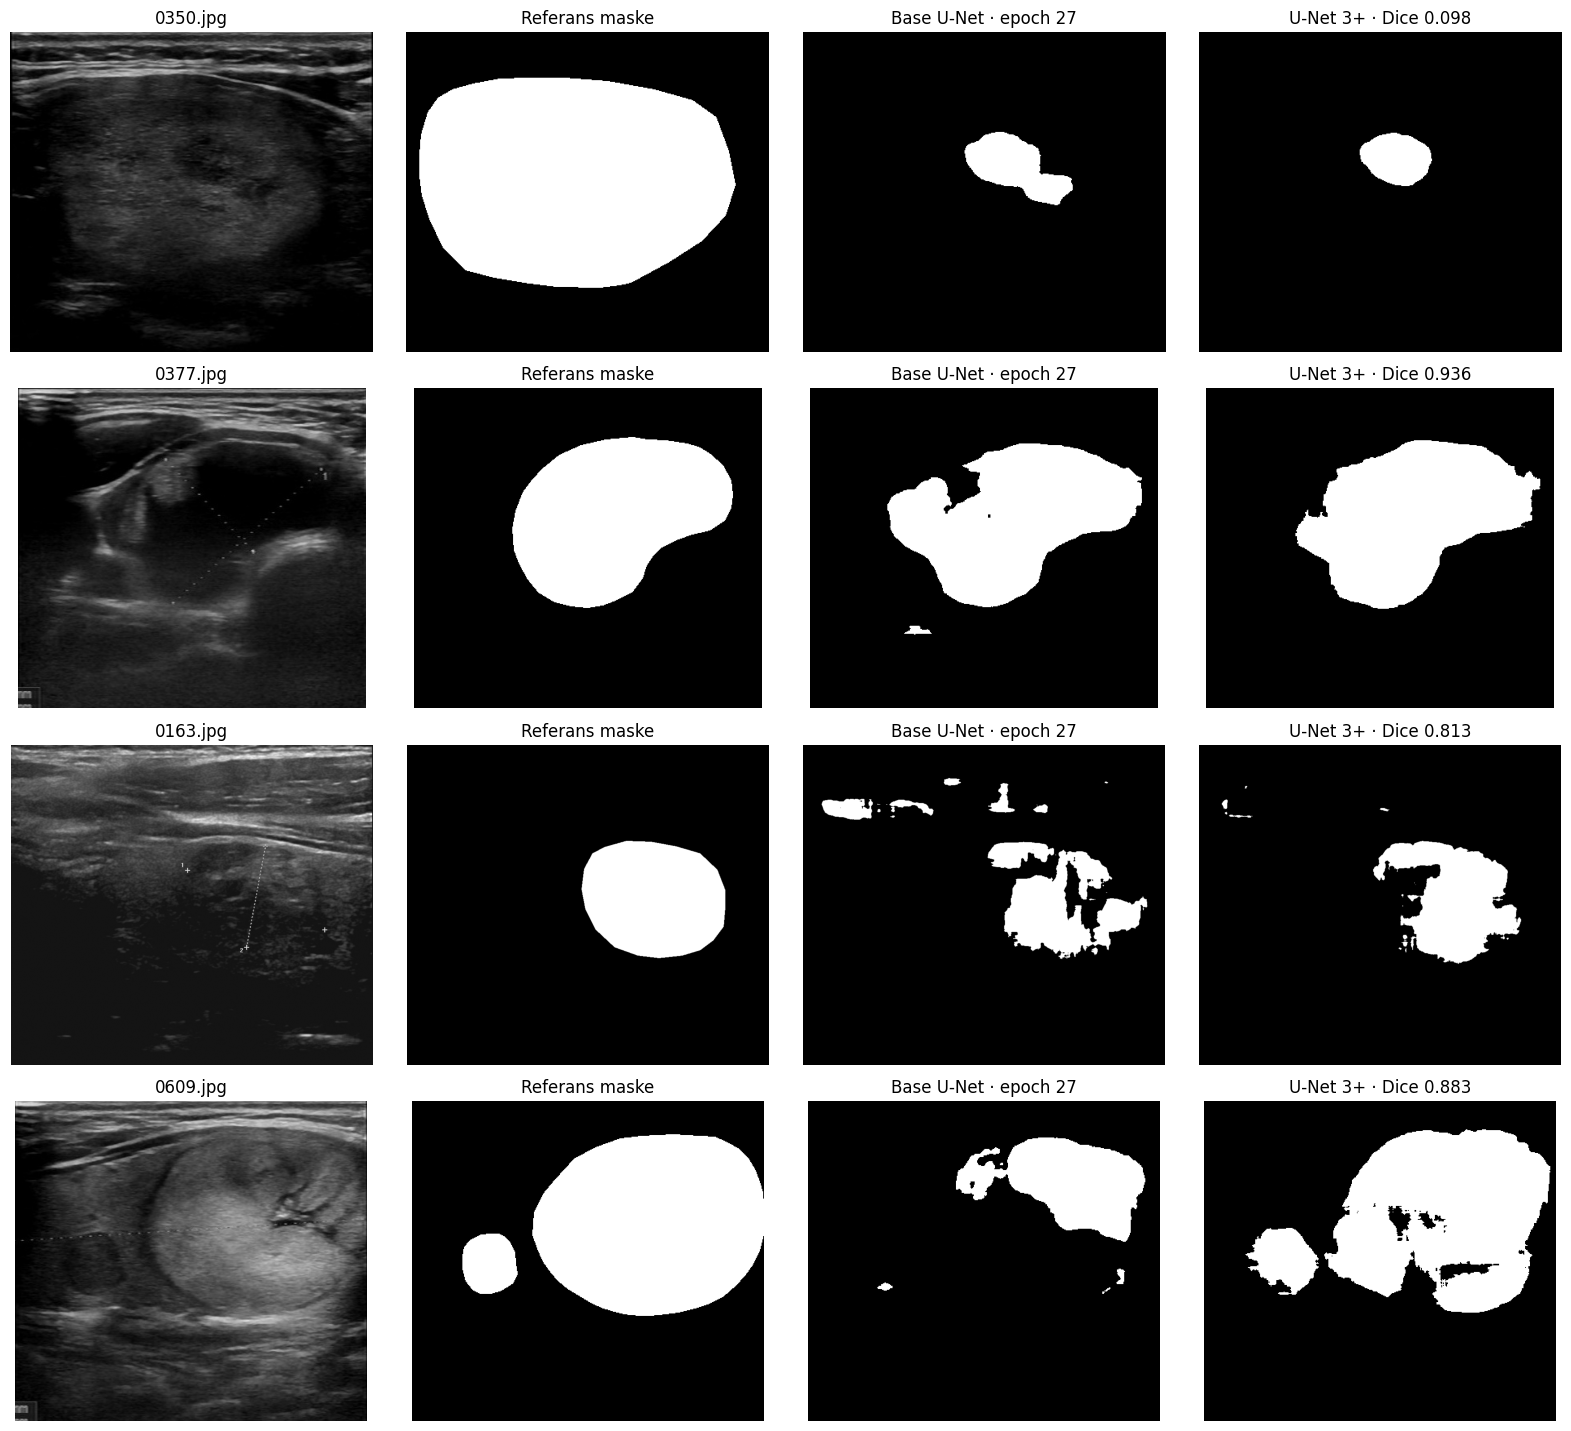

,Model,Checkpoint epoch,Test görüntüsü,Dice,IoU,HD95 (özgün px),Sonlu HD95 ort. (özgün px),Sonlu olmayan HD95,Durum
0,Base U-Net,27,614,0.7498,0.6413,93.5656,93.5656,0,Doğrulandı
1,U-Net 3+,62,614,0.7777,0.6751,81.0360,81.0360,0,Tamamlandı


U-Net 3+ − Base U-Net | Dice: +2.79 yüzde puan | IoU: +3.38 yüzde puan.
HD95 farkı: -12.53 piksel. Daha düşük HD95, daha yakın maske sınırları demektir.
Bu sonuçlar aynı 614 görüntüde aynı ön işleme ve metriklerle ölçülen iki checkpoint’i karşılaştırır. Eğitim bütçeleri farklı olduğu için skor farkı tek başına mimarinin etkisini ölçmez.
Kayıt klasörü: /content/drive/MyDrive/TN3K/UNet3/Test_Sonuclari/UNet3Plus_Epoch62_20261125T123222Z_a00d3cc1


In [8]:
EXPECTED_BASE_CHECKPOINT_SHA256 = 'e6d0b8f57f103b6203b0540b48e3dcea64654c7fc7ae97f9dc6deafd72e21424'

base_summary_path = BASE_RESULTS_DIR / "summary.json"
base_csv_path = BASE_RESULTS_DIR / "per_image_metrics.csv"
base_results = None
base_metrics = None
base_note = ""
try:
    require_files(base_summary_path, base_csv_path)
    base_summary = read_json(base_summary_path)
    if (base_summary["status"] != "completed" or base_summary["checkpoint_epoch"] != 27
            or base_summary["checkpoint_sha256"] != EXPECTED_BASE_CHECKPOINT_SHA256
            or base_summary["manifest_sha256"] != EXPECTED_MANIFEST_SHA256
            or base_summary["processed_test_images"] != 614 or base_summary["amp_enabled"]
            or any(base_summary["checkpoint_config"].get(key) != base_test_protocol[key] for key in protocol_keys)):
        raise ValueError(f"Epoch 27, manifest veya test protokolü {base_summary_path} ile doğrulanamadı.")
    candidate = pd.read_csv(base_csv_path, dtype={"filename": str})
    if not expected_ids.equals(candidate[identity].sort_values(identity).reset_index(drop=True)):
        raise ValueError(f"614 örneğin kimlikleri manifestle eşleşmiyor: {base_csv_path}")
    calculated = summarize_metrics(candidate)
    for key, value in calculated.items():
        saved = base_summary["all"][key]
        if value is None or saved is None:
            matches = value is saved
        else:
            matches = math.isclose(value, saved, rel_tol=0, abs_tol=1e-8)
        if not matches:
            raise ValueError(f"{key} değeri {base_summary_path.name} ile {base_csv_path.name} arasında farklı.")
    base_metrics = calculated
    base_results = candidate
    print("Base U-Net epoch 27 doğrulandı. İki değerlendirmede aynı 614 görüntü var.")
except (OSError, ValueError, KeyError, TypeError) as error:
    base_note = str(error)
    print(f"Base U-Net karşılaştırması bekliyor: {base_note}")

examples = results.sample(n=4, random_state=cfg.seed).merge(
    test_table[["split", "filename", "image_path", "mask_path"]], on=["split", "filename"],
    validate="one_to_one",
)
base_masks = []
if base_results is not None:
    base_files = base_results.set_index(["split", "filename"])["prediction_file"]
    for row in examples.itertuples(index=False):
        path = BASE_RESULTS_DIR / "predictions" / base_files.loc[(row.split, row.filename)]
        try:
            with Image.open(path) as saved:
                base_masks.append(np.array(saved.convert("L")) > 0)
        except OSError as error:
            print(f"Base maskesi açılamadı: {path} | {error}")
            base_masks.append(None)
    for index, row in enumerate(examples.itertuples(index=False)):
        mask = base_masks[index]
        if mask is not None and mask.shape != read_image_mask(row.image_path, row.mask_path, cfg)[0].shape:
            print(f"Base maskesinin özgün boyutu yanlış: {row.filename}")
            base_masks[index] = None
else:
    print("Ortak örnek görseli için doğrulanmış Base CSV’si, özeti ve predictions/*.png dosyaları gerekir.")

show_base = any(mask is not None for mask in base_masks)
if not show_base:
    print("U-Net 3+ tahminleri, erişilebilir referans maskelerle gösteriliyor.")
fig, axes = plt.subplots(len(examples), 4 if show_base else 3,
                         figsize=(16 if show_base else 12, 3.6 * len(examples)), squeeze=False)
for i, (panel, row) in enumerate(zip(axes, examples.itertuples(index=False))):
    image, target = read_image_mask(row.image_path, row.mask_path, cfg)
    with Image.open(prediction_dir / row.prediction_file) as saved:
        prediction = np.array(saved.convert("L")) > 0
    views = [(image, row.filename, 255), (target, "Referans maske", 1)]
    if show_base:
        views.append((base_masks[i], "Base U-Net · epoch 27", 1))
    views.append((prediction, f"U-Net 3+ · Dice {row.dice:.3f}", 1))
    for axis, (array, title, maximum) in zip(panel, views):
        if array is None:
            axis.text(0.5, 0.5, "Tahmin dosyası yok", ha="center", va="center")
        else:
            axis.imshow(array, cmap="gray", vmin=0, vmax=maximum)
        axis.set_title(title)
        axis.axis("off")
fig.tight_layout()
fig.savefig(run_dir / "prediction_comparison.png", dpi=cfg.figure_dpi)
plt.show()

def comparison_row(name, epoch, metrics, note):
    metrics = metrics or {}
    return {
        "Model": name, "Checkpoint epoch": epoch, "Test görüntüsü": metrics.get("images"),
        "Dice": metrics.get("dice_mean"), "IoU": metrics.get("iou_mean"),
        "HD95 (özgün px)": metrics.get("hd95_mean_px"),
        "Sonlu HD95 ort. (özgün px)": metrics.get("hd95_finite_mean_px"),
        "Sonlu olmayan HD95": metrics.get("hd95_nonfinite_cases"),
        "Durum": note,
    }

comparison = pd.DataFrame([
    comparison_row("Base U-Net", 27, base_metrics, base_note or "Doğrulandı"),
    comparison_row("U-Net 3+", best_epoch, summary["all"], "Tamamlandı"),
])
comparison.to_csv(run_dir / "model_comparison.csv", index=False)
display(comparison.round(4))

if base_metrics is not None:
    dice_delta = 100 * (summary["all"]["dice_mean"] - base_metrics["dice_mean"])
    iou_delta = 100 * (summary["all"]["iou_mean"] - base_metrics["iou_mean"])
    print(f"U-Net 3+ − Base U-Net | Dice: {dice_delta:+.2f} yüzde puan | IoU: {iou_delta:+.2f} yüzde puan.")
    base_hd, new_hd = base_metrics["hd95_mean_px"], summary["all"]["hd95_mean_px"]
    if base_hd is not None and new_hd is not None:
        print(f"HD95 farkı: {new_hd - base_hd:+.2f} piksel. Daha düşük HD95, daha yakın maske sınırları demektir.")
    else:
        print("Sonlu olmayan HD95 varsa genel ortalama verilmez. Sonlu ortalama ve vaka sayısına birlikte bak.")
    print("Bu sonuçlar aynı 614 görüntüde aynı ön işleme ve metriklerle ölçülen iki checkpoint’i karşılaştırır. "
          "Eğitim bütçeleri farklı olduğu için skor farkı tek başına mimarinin etkisini ölçmez.")
print("Kayıt klasörü:", run_dir)

Aynı test görüntülerindeki tahminleri yan yana incelediğimde, U-Net 3+’ın bazı örneklerde nodül alanını daha iyi kapsadığını ve referans maske dışındaki işaretlemeleri azalttığını gördüm. Bununla birlikte 0350.jpg örneğinde iki model de referans alanın büyük bölümünü kaçırdı ve U-Net 3+ daha düşük Dice aldı. Bu dört örnek, 614 görüntü üzerinden hesaplanan ortalama sonuçların yanında, modellerin hangi tür hataları yaptığını görsel olarak gösteriyor.

,U-Net 3+ daha iyi,Base U-Net daha iyi,Eşit,Ortalama fark,Medyan fark
Dice farkı (yp),388,225,1,2.79,1.46
IoU farkı (yp),388,225,1,3.38,2.13
HD95 azalması (px),371,239,4,12.53,2.09


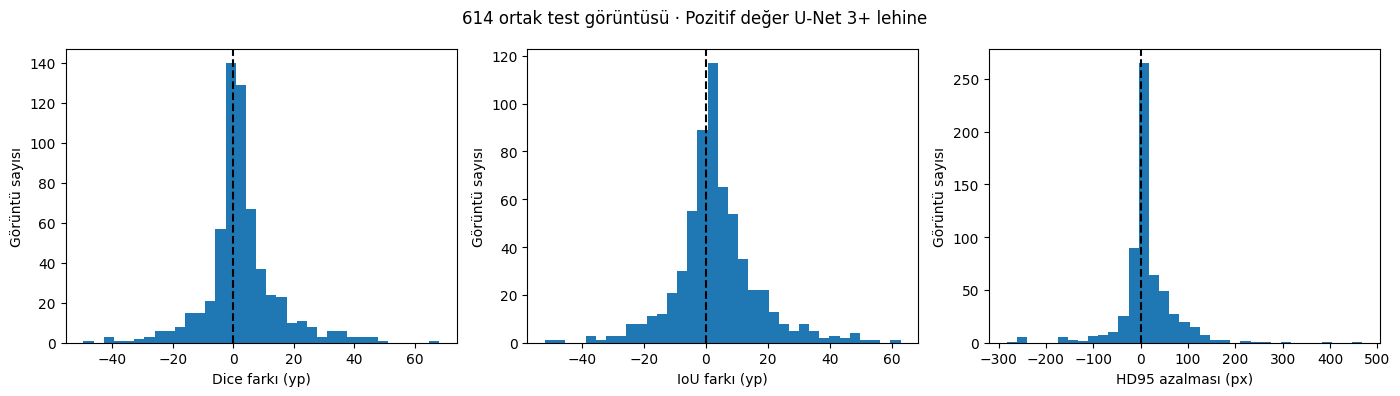

Dice açısından en çok iyileşen 5 görüntü


,filename,dice_base,dice_plus,Dice farkı (yp)
31,0031.jpg,0.1512,0.8311,67.9866
607,0607.jpg,0.3791,0.8665,48.7401
559,0559.jpg,0.3892,0.8475,45.8359
183,0183.jpg,0.4482,0.9032,45.5004
355,0355.jpg,0.2233,0.6723,44.9004


Dice açısından en çok gerileyen 5 görüntü


,filename,dice_base,dice_plus,Dice farkı (yp)
117,0117.jpg,0.8440,0.3481,-49.5878
606,0606.jpg,0.6996,0.2743,-42.5263
605,0605.jpg,0.6587,0.2343,-42.4460
271,0271.jpg,0.6665,0.2709,-39.5606
343,0343.jpg,0.8857,0.4952,-39.0434


In [9]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

root = Path("/content/drive/MyDrive/TN3K")
base_dir = root / "BaseUNet/Test_Sonuclari/Base_UNet_Epoch27_20261124T160223Z_a8532dfd"
plus_dir = root / "UNet3/Test_Sonuclari/UNet3Plus_Epoch62_20261125T123222Z_a00d3cc1"

base = pd.read_csv(base_dir / "per_image_metrics.csv")
plus = pd.read_csv(plus_dir / "per_image_metrics.csv")

keys = ["split", "filename", "image_hash"]
paired = base.merge(plus, on=keys, suffixes=("_base", "_plus"), validate="one_to_one")

if not len(base) == len(plus) == len(paired) == 614:
    raise ValueError("İki CSV aynı 614 görüntüyle birebir eşleşmedi.")

# Üç metrikte de pozitif değer U-Net 3+ lehine.
paired["Dice farkı (yp)"] = 100 * (paired["dice_plus"] - paired["dice_base"])
paired["IoU farkı (yp)"] = 100 * (paired["iou_plus"] - paired["iou_base"])
paired["HD95 azalması (px)"] = paired["hd95_px_base"] - paired["hd95_px_plus"]

metrics = ["Dice farkı (yp)", "IoU farkı (yp)", "HD95 azalması (px)"]
tol = 1e-7
display(pd.DataFrame({
    "U-Net 3+ daha iyi": paired[metrics].gt(tol).sum(),
    "Base U-Net daha iyi": paired[metrics].lt(-tol).sum(),
    "Eşit": paired[metrics].abs().le(tol).sum(),
    "Ortalama fark": paired[metrics].mean(),
    "Medyan fark": paired[metrics].median(),
}).round(2))

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, metric in zip(axes, metrics):
    ax.hist(paired[metric], bins=35)
    ax.axvline(0, color="black", linestyle="--")
    ax.set(xlabel=metric, ylabel="Görüntü sayısı")
fig.suptitle("614 ortak test görüntüsü · Pozitif değer U-Net 3+ lehine")
fig.tight_layout()
plt.show()

columns = ["filename", "dice_base", "dice_plus", "Dice farkı (yp)"]
print("Dice açısından en çok iyileşen 5 görüntü")
display(paired.nlargest(5, "Dice farkı (yp)")[columns].round(4))
print("Dice açısından en çok gerileyen 5 görüntü")
display(paired.nsmallest(5, "Dice farkı (yp)")[columns].round(4))

U-Net 3+ modeli, 614 ortak test görüntüsünün 388’inde Base U-Net’e göre daha yüksek Dice elde etti. Ortalama Dice farkı 2,79, medyan fark ise 1,46 yüzde puandı. Bununla birlikte 225 görüntüde Base U-Net daha yüksek Dice verdi. Dolayısıyla üstünlük, test edilen iki checkpoint için veri kümesi düzeyinde gözlendi ve görüntüler arasında değişkenlik gösterdi

## Örnek bazında hata analizi

Aynı 614 test görüntüsünde Base U-Net ve U-Net 3+ arasındaki Dice farkını
hesapladım. Görsel inceleme için U-Net 3+’ın en çok iyileştiği ve en çok
gerilediği görüntüyü seçtim. Bunlar farkın uç örnekleridir. Genel performansı
614 görüntü üzerinden hesaplanan metriklerle değerlendirdim.

Her satırda özgün ultrason, referans maske ve iki modelin hata haritası yer alıyor.
Hata haritalarında **yeşil** doğru işaretlenen alanı, **kırmızı** referans dışında
işaretlenen alanı, **mavi** ise referans maskede bulunup modelin kaçırdığı alanı
gösteriyor.

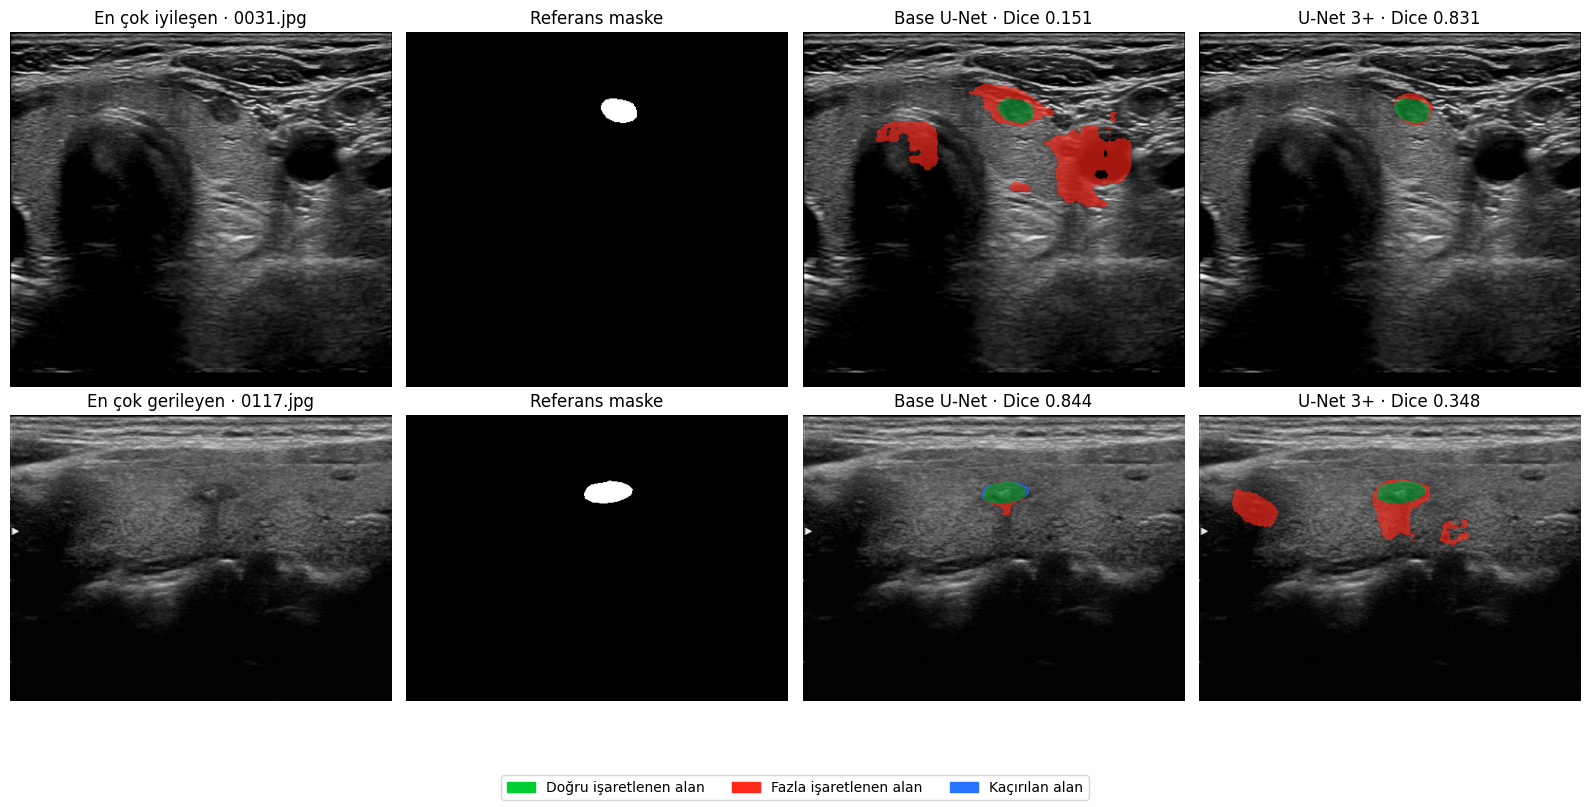

Görsel ve örnek tablosu kaydedildi: /content/drive/MyDrive/TN3K/UNet3/Test_Sonuclari/UNet3Plus_Epoch62_20261125T123222Z_a00d3cc1/Eslesmis_Analiz


In [10]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch
from PIL import Image

project = Path("/content/drive/MyDrive/TN3K")
base_dir = project / "BaseUNet/Test_Sonuclari/Base_UNet_Epoch27_20261124T160223Z_a8532dfd"
plus_dir = project / "UNet3/Test_Sonuclari/UNet3Plus_Epoch62_20261125T123222Z_a00d3cc1"

if "data_root" not in globals() or not (Path(data_root) / "test-image").is_dir():
    import kagglehub

    data_root = Path(kagglehub.dataset_download(
        "tjahan/tn3k-thyroid-nodule-region-segmentation-dataset/versions/2"
    ))

keys = ["split", "filename", "image_hash"]
columns = keys + ["dice", "prediction_file"]
base = pd.read_csv(base_dir / "per_image_metrics.csv", usecols=columns)
plus = pd.read_csv(plus_dir / "per_image_metrics.csv", usecols=columns)
paired = base.merge(plus, on=keys, suffixes=("_base", "_plus"), validate="one_to_one")

if not len(base) == len(plus) == len(paired) == 614:
    raise ValueError("İki test kaydı aynı 614 görüntüyle eşleşmedi.")

paired["dice farkı (yp)"] = 100 * (paired["dice_plus"] - paired["dice_base"])
examples = pd.concat([
    paired.nlargest(1, "dice farkı (yp)").assign(example_type="En çok iyileşen"),
    paired.nsmallest(1, "dice farkı (yp)").assign(example_type="En çok gerileyen"),
])


def read_gray(path):
    if not path.is_file():
        raise FileNotFoundError(f"Görüntü veya maske bulunamadı: {path}")
    with Image.open(path) as image:
        return np.array(image.convert("L"))


def draw_errors(axis, image, target, prediction):
    overlay = np.zeros((*target.shape, 4), dtype=float)
    overlay[target & prediction] = (0.0, 0.8, 0.2, 0.45)
    overlay[~target & prediction] = (1.0, 0.15, 0.1, 0.65)
    overlay[target & ~prediction] = (0.15, 0.45, 1.0, 0.65)
    axis.imshow(image, cmap="gray", vmin=0, vmax=255)
    axis.imshow(overlay)


fig, axes = plt.subplots(len(examples), 4, figsize=(16, 8), squeeze=False)

for panel, (_, row) in zip(axes, examples.iterrows()):
    name = row["filename"]
    image = read_gray(Path(data_root) / "test-image" / name)
    target = read_gray(Path(data_root) / "test-mask" / name) >= 128
    base_mask = read_gray(base_dir / "predictions" / row["prediction_file_base"]) > 0
    plus_mask = read_gray(plus_dir / "predictions" / row["prediction_file_plus"]) > 0

    if not image.shape == target.shape == base_mask.shape == plus_mask.shape:
        raise ValueError(f"Özgün görüntü ve maske boyutları eşleşmedi: {name}")

    panel[0].imshow(image, cmap="gray", vmin=0, vmax=255)
    panel[0].set_title(f"{row['example_type']} · {name}")
    panel[1].imshow(target, cmap="gray", vmin=0, vmax=1)
    panel[1].set_title("Referans maske")

    draw_errors(panel[2], image, target, base_mask)
    panel[2].set_title(f"Base U-Net · Dice {row['dice_base']:.3f}")
    draw_errors(panel[3], image, target, plus_mask)
    panel[3].set_title(f"U-Net 3+ · Dice {row['dice_plus']:.3f}")

    for axis in panel:
        axis.axis("off")

fig.legend(
    handles=[
        Patch(color="#00cc33", label="Doğru işaretlenen alan"),
        Patch(color="#ff261a", label="Fazla işaretlenen alan"),
        Patch(color="#2673ff", label="Kaçırılan alan"),
    ],
    loc="lower center",
    ncol=3,
)
fig.tight_layout(rect=(0, 0.06, 1, 1))

analysis_dir = plus_dir / "Eslesmis_Analiz"
analysis_dir.mkdir(exist_ok=True)
figure_path = analysis_dir / "dice_uc_ornekler.png"
fig.savefig(figure_path, dpi=180, bbox_inches="tight")
plt.show()

examples[["example_type", "filename", "dice_base", "dice_plus", "dice farkı (yp)"]].to_csv(
    analysis_dir / "dice_uc_ornekler.csv", index=False
)
print("Görsel ve örnek tablosu kaydedildi:", analysis_dir)

### Sonuçların yorumu

U-Net 3+, 614 ortak test görüntüsünün 388’inde daha yüksek Dice elde etti.
225 görüntüde Base U-Net daha yüksek Dice verdi ve bir görüntüde skorlar eşitti.
Ortalama fark U-Net 3+ lehine 2,79 yüzde puan, medyan fark ise 1,46 yüzde puandı.

Görsel inceleme bu farkın iki yönünü gösteriyor. En çok iyileşen `0031.jpg`
örneğinde Dice 0,151’den 0,831’e yükseldi. En çok gerileyen `0117.jpg` örneğinde
ise 0,844’ten 0,348’e düştü. Hata haritaları bu değişimleri, modelin kaçırdığı
referans pikselleri ve referans dışında işaretlediği pikseller üzerinden
incelemeyi sağlıyor.

Bu sonuçlar, değerlendirilen U-Net 3+ ağırlığının TN3K test kümesinde ortalamada
daha iyi örtüşme sağladığını, ancak kazancın görüntüden görüntüye değiştiğini
gösteriyor. İki checkpoint farklı eğitim bütçeleriyle elde edildiği için farkı
yalnızca mimariye atfedemiyorum.

## Ek örneklerde piksel bazlı hata analizi

Dice farkına göre ikinci ve üçüncü sıradaki iyileşen ve gerileyen görüntüleri
inceliyorum. Her örnekte iki modelin fazla işaretlediği ve kaçırdığı bölgeleri
aynı referans maskeye göre karşılaştırıyorum. Bu örnekler, büyük skor
değişimlerini açıklamak için seçildi.

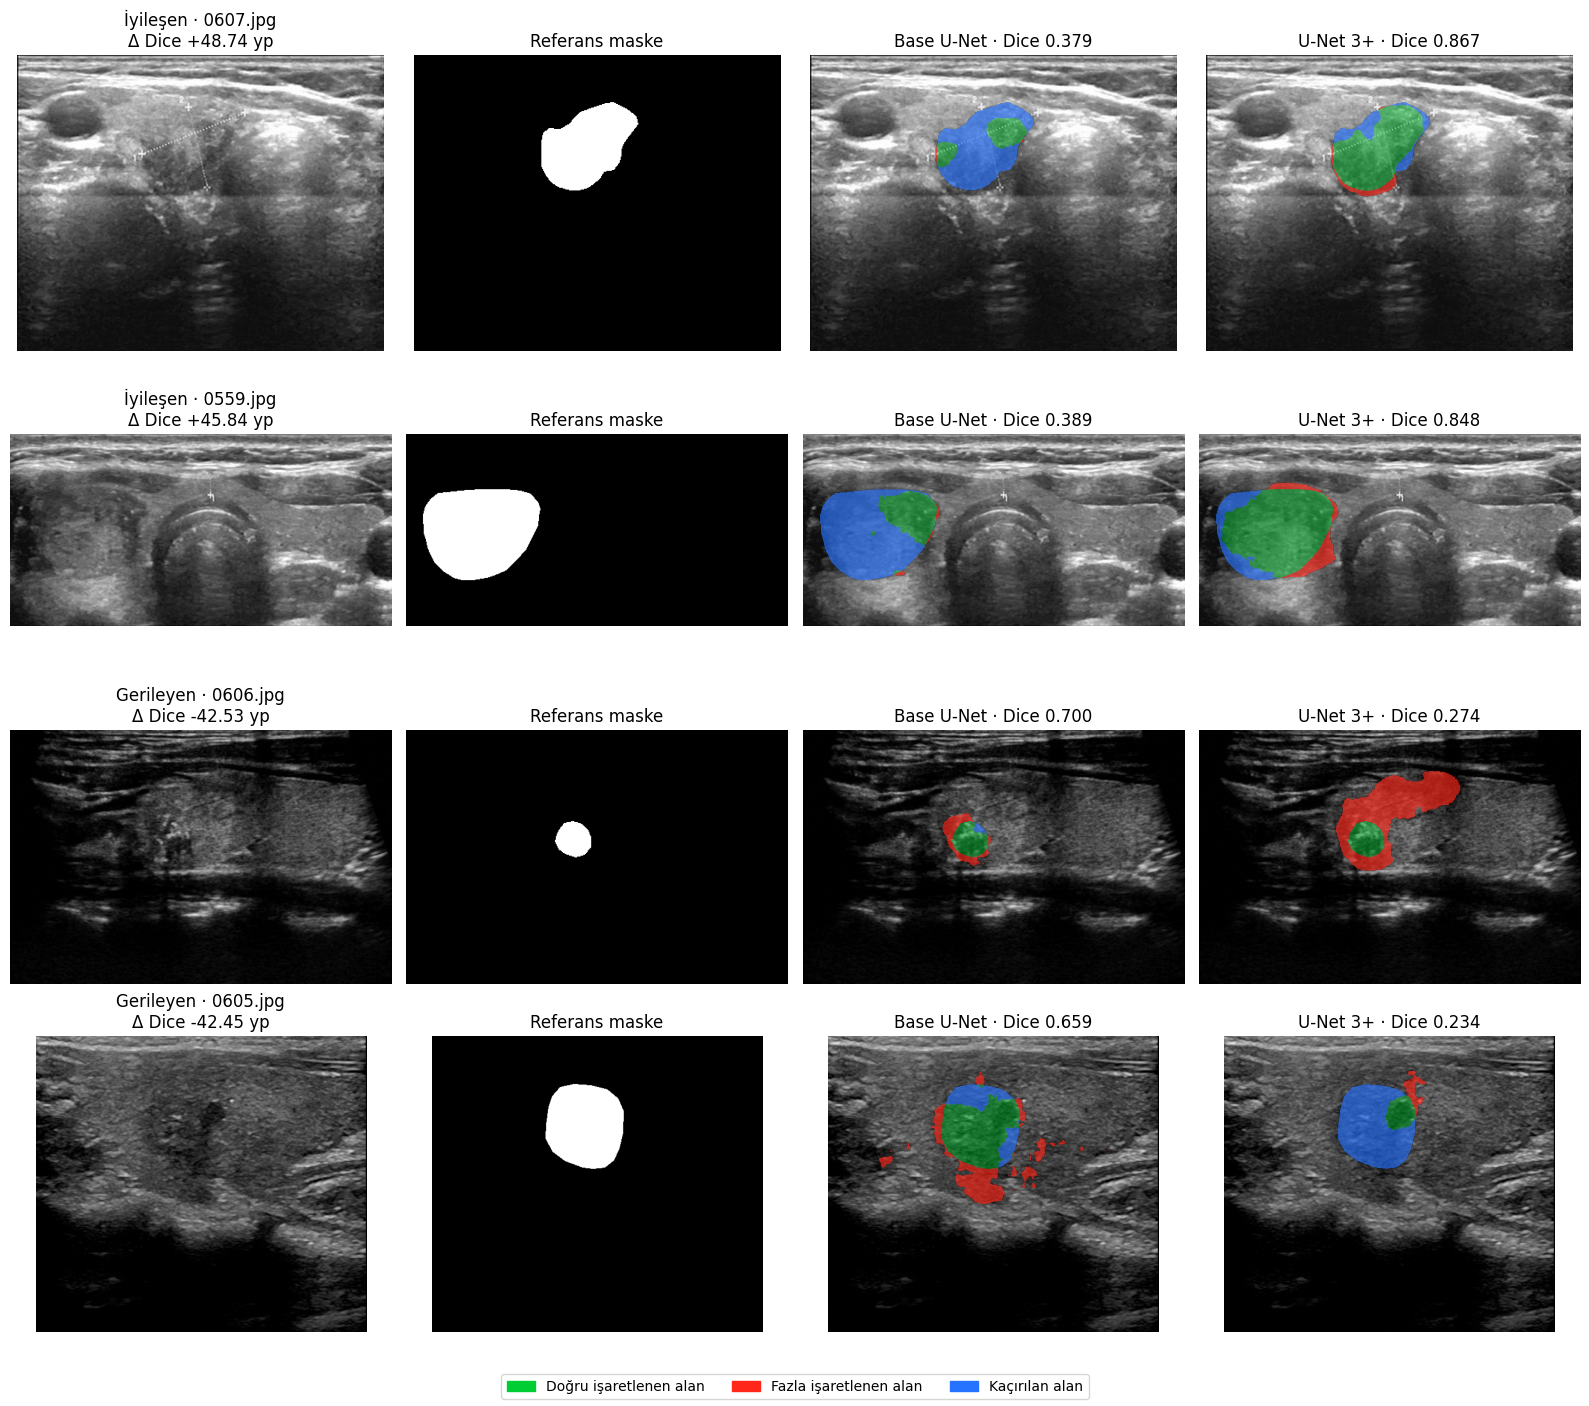

İncelenen örnekler: 0607.jpg, 0559.jpg, 0606.jpg, 0605.jpg
PNG ve CSV kaydedildi: /content/drive/MyDrive/TN3K/UNet3/Test_Sonuclari/UNet3Plus_Epoch62_20261125T123222Z_a00d3cc1/Eslesmis_Analiz


In [18]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch
from PIL import Image

project = Path("/content/drive/MyDrive/TN3K")
base_dir = project / "BaseUNet/Test_Sonuclari/Base_UNet_Epoch27_20261124T160223Z_a8532dfd"
plus_dir = project / "UNet3/Test_Sonuclari/UNet3Plus_Epoch62_20261125T123222Z_a00d3cc1"

keys = ["split", "filename", "image_hash"]
columns = keys + ["dice", "prediction_file"]
base = pd.read_csv(base_dir / "per_image_metrics.csv", usecols=columns)
plus = pd.read_csv(plus_dir / "per_image_metrics.csv", usecols=columns)
paired = base.merge(
    plus, on=keys, suffixes=("_base", "_plus"), validate="one_to_one"
)

if not len(base) == len(plus) == len(paired) == 614:
    raise ValueError("İki CSV aynı 614 test görüntüsünde eşleşmedi.")

delta = "Dice farkı (yüzde puan)"
paired[delta] = 100 * (paired["dice_plus"] - paired["dice_base"])
examples = pd.concat(
    [
        paired.nlargest(3, delta).iloc[1:3].assign(grup="İyileşen"),
        paired.nsmallest(3, delta).iloc[1:3].assign(grup="Gerileyen"),
    ],
    ignore_index=True,
)

dataset_dir = Path(globals().get("data_root") or "/content/tn3k")
if not all((dataset_dir / name).is_dir() for name in ("test-image", "test-mask")):
    import kagglehub

    dataset_dir = Path(kagglehub.dataset_download(
        "tjahan/tn3k-thyroid-nodule-region-segmentation-dataset/versions/2"
    ))


def read_gray(path):
    if not path.is_file():
        raise FileNotFoundError(f"Görüntü veya maske bulunamadı: {path}")
    with Image.open(path) as image:
        return np.array(image.convert("L"))


# Görselleri figürü açmadan önce yükle. Eksik dosyada Colab doğrudan dosya yolunu gösterir.
loaded = []
for row in examples.to_dict("records"):
    name = row["filename"]
    image = read_gray(dataset_dir / "test-image" / name)
    target = read_gray(dataset_dir / "test-mask" / name) >= 128
    base_mask = read_gray(base_dir / "predictions" / row["prediction_file_base"]) > 0
    plus_mask = read_gray(plus_dir / "predictions" / row["prediction_file_plus"]) > 0

    if not image.shape == target.shape == base_mask.shape == plus_mask.shape:
        raise ValueError(f"Görüntü ve maskelerin boyutları eşleşmedi: {name}")

    loaded.append((row, image, target, base_mask, plus_mask))


def draw_errors(axis, image, target, prediction):
    overlay = np.zeros((*target.shape, 4), dtype=np.float32)
    overlay[target & prediction] = (0.0, 0.8, 0.2, 0.45)
    overlay[~target & prediction] = (1.0, 0.15, 0.1, 0.65)
    overlay[target & ~prediction] = (0.15, 0.45, 1.0, 0.65)
    axis.imshow(image, cmap="gray", vmin=0, vmax=255)
    axis.imshow(overlay)


fig, axes = plt.subplots(len(loaded), 4, figsize=(16, 14), squeeze=False)

for panel, (row, image, target, base_mask, plus_mask) in zip(axes, loaded):
    panel[0].imshow(image, cmap="gray", vmin=0, vmax=255)
    panel[0].set_title(f"{row['grup']} · {row['filename']}\nΔ Dice {row[delta]:+.2f} yp")

    panel[1].imshow(target, cmap="gray", vmin=0, vmax=1)
    panel[1].set_title("Referans maske")

    draw_errors(panel[2], image, target, base_mask)
    panel[2].set_title(f"Base U-Net · Dice {row['dice_base']:.3f}")

    draw_errors(panel[3], image, target, plus_mask)
    panel[3].set_title(f"U-Net 3+ · Dice {row['dice_plus']:.3f}")

    for axis in panel:
        axis.axis("off")

fig.legend(
    handles=[
        Patch(color="#00cc33", label="Doğru işaretlenen alan"),
        Patch(color="#ff261a", label="Fazla işaretlenen alan"),
        Patch(color="#2673ff", label="Kaçırılan alan"),
    ],
    loc="lower center",
    ncol=3,
)
fig.tight_layout(rect=(0, 0.04, 1, 1))

analysis_dir = plus_dir / "Eslesmis_Analiz"
analysis_dir.mkdir(exist_ok=True)
fig.savefig(analysis_dir / "dice_ek_ornekler.png", dpi=180, bbox_inches="tight")
examples[["grup", "filename", "dice_base", "dice_plus", delta]].to_csv(
    analysis_dir / "dice_ek_ornekler.csv", index=False
)

plt.show()
print("İncelenen örnekler:", ", ".join(examples["filename"]))
print("PNG ve CSV kaydedildi:", analysis_dir)